# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


## Setup

In [2]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [3]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = "HeCBench"  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = "jacobi"  # "mandelbrot"  # "raytracing/raytracing_cuda"  # "lid-driven-cavity"   #  "bfs"
    app_name = "jacobi-cuda_main"  # "bfs"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto1mini"  # (max token = 128000)
    model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview", "gpto1mini"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "04test_o1p_ee_hecb-jacobi-params"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: jacobi

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto1mini
Model coder: gpto1mini
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto1mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp04test_o1p_ee_hecb-jacobi-params

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

LLM Prompt for Code Generation: 

Carefully follow all these instructions step-by-step: 
STEP 1. Read the background knowledge and your background knowledge summaries about programming and energy-efficiency strategies. 
STEP 2. Read your description and analysis of the source code'

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/jacobi
Execute command: ['./jacobi-cuda_main', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00980293 (s)
PASS
Total elapsed time: 17.48 seconds
GPU power data has been written to source_CUDA_gpu_power_results.csv


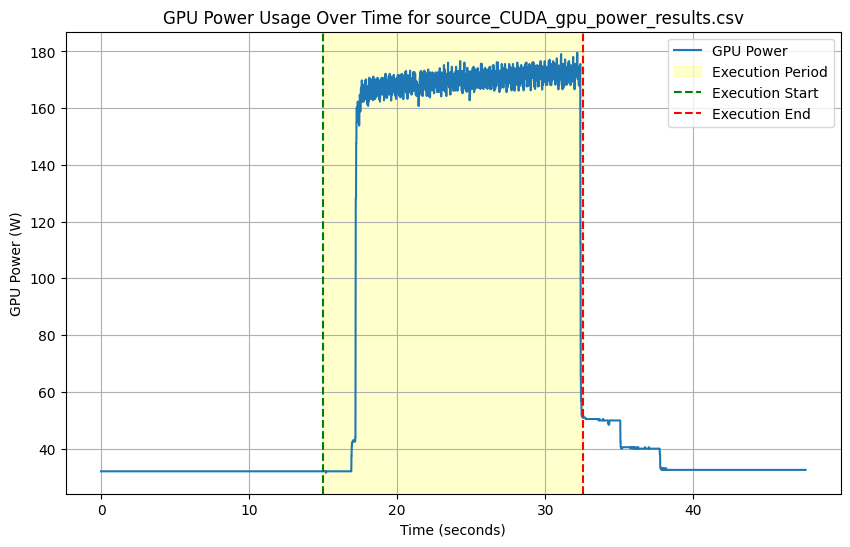

Start time: 15.001 -- End time: 32.57
Code execution duration: 17.57 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000746 kWh
  0.7460 Wh
  2685.51 J
Average GPU power: 153.09 W
Total Energy During Exe Runtime:   2685.51 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 17.57
GPU power data has been written to idle__gpu_power_results.csv


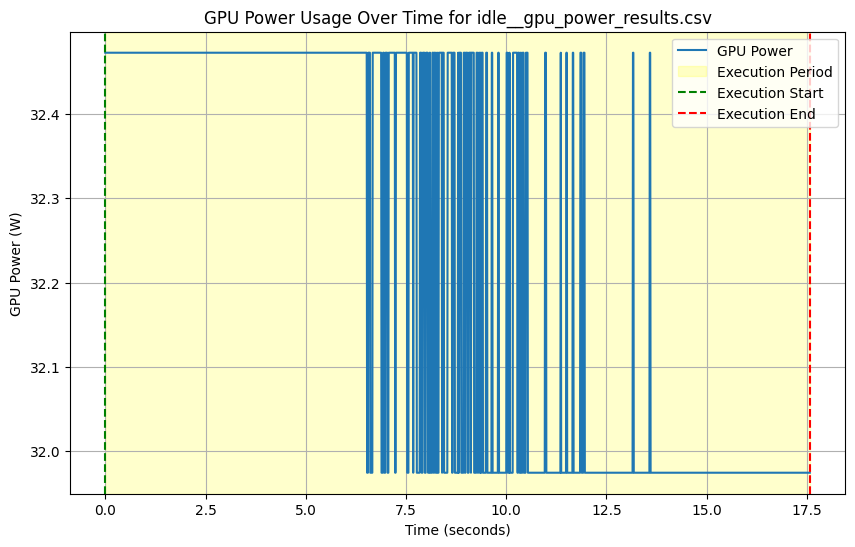

Start time: 0 -- End time: 17.57
Code execution duration: 17.57 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000157 kWh
  0.1572 Wh
  565.95 J
Average GPU power: 32.23 W
Total Energy During Exe Runtime:   565.95 J
----------------------------------------------------------------------------------------------------------------------------------------




----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----


--> ... prompt LLM to summarize context knowledge.

To effectively refactor CUDA C++ code for improved **energy efficiency**, it is essential to apply best practices and optimization strategies that minimize resource consumption while maintaining or enhancing performance. Below is a summary of the key relevant points derived from the provided background knowledge:

### 1. **Minimize Data Transfers Between Host and Device**
- **Avoid Unnecessary Transfers:** Data movement between the host (CPU) and device (GPU) is energy-intensive. Ensure that int

To effectively refactor CUDA C++ code for improved **energy efficiency**, it is essential to apply best practices and optimization strategies that minimize resource consumption while maintaining or enhancing performance. Below is a summary of the key relevant points derived from the provided background knowledge:

### 1. **Minimize Data Transfers Between Host and Device**
- **Avoid Unnecessary Transfers:** Data movement between the host (CPU) and device (GPU) is energy-intensive. Ensure that intermediate data structures remain on the device without being mapped or copied back to the host.
- **Batch Transfers:** Consolidate multiple small data transfers into larger, contiguous ones to reduce overhead and energy consumption.
- **Use Page-Locked (Pinned) Memory:** Facilitates higher bandwidth transfers, leading to more efficient data movement and reduced energy usage.

### 2. **Optimize Memory Usage**
- **Prefer Shared Memory Over Global Memory:**
  - **Lower Latency:** Shared memory is closer to the processing cores, resulting in faster access and lower energy consumption compared to global memory.
  - **Reduce Global Memory Accesses:** Limit the use of global memory as it incurs higher latency and energy costs.
- **Leverage Memory Hierarchy Effectively:**
  - **Utilize Constant and Texture Memory:** These read-only memory spaces are optimized for specific access patterns and can contribute to energy savings.
  - **Avoid Automatic Conversion of Data Types:** Prevent unnecessary type conversions (e.g., double to float) to reduce additional memory operations and energy usage.

### 3. **Enhance Thread and Block Configuration**
- **Maintain High Occupancy:**
  - **Sufficient Active Threads:** Ensures that processing units are utilized effectively, hiding memory latencies and reducing idle energy consumption.
- **Optimal Threads per Block:**
  - **Multiples of Warp Size (32):** Aligning threads per block to warp multiples enhances computing efficiency and minimizes energy waste.
- **Use Thread Block Clusters (Compute Capability 9.0 and Above):**
  - **Co-scheduling on GPU Processing Clusters:** Improves synchronization and memory access patterns, leading to more energy-efficient executions.

### 4. **Avoid Warp Divergence**
- **Consistent Execution Paths Within Warps:**
  - **Minimize Control Flow Variations:** Divergent branches within a warp force serialization of execution paths, increasing both execution time and energy consumption.
  - **Employ Predication and __syncwarp():** Where divergence is unavoidable, use compiler optimizations and synchronization primitives to manage execution efficiently.

### 5. **Utilize Fast and Specialized Math Functions**
- **Prefer Fast Math Over Precision-Intensive Operations:**
  - **Use __functions (e.g., __sinf, __expf):** These functions map directly to hardware instructions, offering lower energy consumption due to reduced computation cycles.
  - **Leverage Specialized Functions (e.g., sincospi):** These provide both performance gains and energy savings by optimizing specific mathematical operations.

### 6. **Efficient Use of Registers and Shared Resources**
- **Manage Register Usage:**
  - **Avoid Register Dependencies:** Reduces the need for serialization and allows for more parallel execution, thereby saving energy.
- **Leverage Cooperative Groups and Synchronization Objects:**
  - **Efficient Synchronization:** Proper synchronization within thread blocks and clusters minimizes idle times and energy wastage.

### 7. **Compute Capability Considerations**
- **Target Appropriate GPU Architectures:**
  - **Optimize for Specific SM Versions:** Tailoring code to leverage the features of the GPU’s compute capability can lead to more energy-efficient executions.
  - **Utilize Advanced Features (e.g., Thread Block Clusters):** Newer architectures offer features that can enhance energy efficiency when properly utilized.

### 8. **General Coding Practices for Energy Efficiency**
- **Use Signed Integers for Loop Counters:** Facilitates compiler optimizations, reducing unnecessary instructions and energy overhead.
- **Avoid Expensive Operations:**
  - **Replace Division and Modulo with Bitwise Operations:** When applicable, using shift and mask operations can lower energy consumption by reducing computational complexity.
- **Simplify Control Structures:**
  - **Enable Branch Predication:** Allows the compiler to manage control flows more efficiently, reducing the energy costs associated with branching.

### 9. **Heterogeneous Programming Optimization**
- **Efficient Memory Management:**
  - **Use Unified Memory Sparingly:** While it simplifies memory management, overuse can lead to unnecessary data movements and increased energy consumption.
- **Balance Workload Between Host and Device:**
  - **Delegate Appropriate Tasks to GPU:** Ensure that only computationally intensive tasks are offloaded to the GPU to maximize energy savings.

---

By adhering to these key practices, developers can refactor CUDA C++ code to achieve significant improvements in energy efficiency. These strategies not only optimize resource utilization but also contribute to sustainable and cost-effective computing solutions.


--> ... prompt LLM to describe the source code.

The provided CUDA C++ program implements a parallel Jacobi iterative solver to perform relaxation on a two-dimensional (2D) grid. This solver is optimized to run efficiently on NVIDIA GPUs by leveraging CUDA's parallel computing capabilities. Below is a detailed description and analysis of the program's complete functionality, including its major functional blocks, classes, functions, and data structures.

### **Overall Functionality**

The program performs Jacobi iterative relaxation on a large 2D grid of size \( N \times N \) (where \( N = 16384 \)). The Jacobi method is an iterative algorithm used to solve systems of linear equations, typically arising from discretizing partial differential equations. In this context, the solver iteratively updates each grid point based on the average of its four neighboring points until the solution converges within a specified tolerance or reaches a maximum number of iterations.

### **Major Functi

The provided CUDA C++ program implements a parallel Jacobi iterative solver to perform relaxation on a two-dimensional (2D) grid. This solver is optimized to run efficiently on NVIDIA GPUs by leveraging CUDA's parallel computing capabilities. Below is a detailed description and analysis of the program's complete functionality, including its major functional blocks, classes, functions, and data structures.

### **Overall Functionality**

The program performs Jacobi iterative relaxation on a large 2D grid of size \( N \times N \) (where \( N = 16384 \)). The Jacobi method is an iterative algorithm used to solve systems of linear equations, typically arising from discretizing partial differential equations. In this context, the solver iteratively updates each grid point based on the average of its four neighboring points until the solution converges within a specified tolerance or reaches a maximum number of iterations.

### **Major Functional Blocks**

1. **Data Initialization**
   - **Function:** `initialize_data(float* f)`
   - **Description:** Initializes the 2D grid with sinusoidal boundary conditions. The boundary points (edges of the grid) are set using sine functions to simulate oscillatory conditions, while the interior points are initialized to zero. This setup provides a starting point for the iterative relaxation process.

2. **Jacobi Iterative Step**
   - **Kernel Function:** `__global__ void jacobi_step(float* __restrict__ f, const float* __restrict__ f_old, float* __restrict__ error)`
   - **Description:** Executes a single Jacobi relaxation step on the GPU. Each thread computes the new value of a grid point by averaging its four immediate neighbors from the previous iteration. The kernel utilizes shared memory (`f_old_tile`) to store a tile of the grid, including a halo region for neighboring data, which reduces global memory accesses and enhances performance. Additionally, each thread calculates the squared difference between the new and old values to monitor convergence, accumulating these errors using warp-level shuffles and atomic operations to update a global error metric.

3. **Data Swapping**
   - **Kernel Function:** `__global__ void swap_data(const float* __restrict__ f, float* __restrict__ f_old)`
   - **Description:** Swaps the roles of the current and previous iteration grids by copying the newly computed values (`f`) back to the old grid (`f_old`). This prepares the data for the next iteration of the Jacobi method.

4. **Main Execution Flow**
   - **Function:** `int main()`
   - **Description:** Orchestrates the overall execution of the program. It performs the following tasks:
     - **Memory Allocation:** Allocates memory on both the host (CPU) and device (GPU) for the grid data (`f` and `f_old`) and the error metric (`error`).
     - **Data Initialization:** Calls `initialize_data` to set up the initial conditions of the grid on the host and copies this data to the GPU.
     - **Kernel Configuration:** Defines the grid and block dimensions for CUDA kernel launches, optimizing for a `16x16` thread block size.
     - **Iterative Loop:** Executes the Jacobi relaxation steps in a loop until the solution converges below a specified tolerance or a maximum number of iterations is reached. In each iteration, it:
       - Resets the error metric on the GPU.
       - Launches the `jacobi_step` kernel to perform relaxation.
       - Launches the `swap_data` kernel to prepare for the next iteration.
       - Copies the accumulated error back to the host and checks for convergence.
       - Periodically prints the current error to monitor progress.
     - **Performance Measurement:** Measures and reports the average execution time per iteration and the total elapsed time using high-resolution timers.
     - **Cleanup:** Frees allocated memory on both the host and device to prevent memory leaks.

### **Key Classes, Functions, and Data Structures**

1. **Macros and Definitions**
   - **`#define N 16384`**
     - **Purpose:** Defines the size of the grid as \( 16384 \times 16384 \). This large grid size is chosen to demonstrate the scalability and performance of the CUDA implementation.
   - **`#define IDX(i, j) ((i) + (j) * N)`**
     - **Purpose:** Calculates the linear index in a one-dimensional array representation of the 2D grid. This macro simplifies access to grid elements during initialization and kernel operations.

2. **Host Functions**
   - **`initialize_data(float* f)`**
     - **Purpose:** Initializes the grid with specific boundary conditions and zeroes for interior points. This function ensures that the Jacobi solver starts with a known initial state.

3. **CUDA Kernel Functions**
   - **`jacobi_step`**
     - **Purpose:** Performs the core computation of the Jacobi method by updating each grid point based on its neighbors. It leverages shared memory for efficient data access and reduces computational overhead by minimizing global memory transactions.
   - **`swap_data`**
     - **Purpose:** Swaps the data between the current and previous iterations, effectively preparing the system for the next relaxation step without additional memory allocations.

4. **Data Structures**
   - **Shared Memory Arrays in `jacobi_step`**
     - **`__shared__ float f_old_tile[18][18];`**
       - **Purpose:** Stores a tile of the grid including a halo region to facilitate neighbor access without additional global memory reads.
     - **`__shared__ float reduction_array[16];`**
       - **Purpose:** Accumulates partial sums of squared differences for error calculation during warp-level reduction.
   - **Grid Representation**
     - The 2D grid is represented as a one-dimensional array of floats on both the host and device. This linear representation simplifies memory allocation and access patterns in CUDA.

5. **Memory Management**
   - **Host Memory Allocation**
     - **`float* f` and `float* f_old`**
       - **Purpose:** Allocate aligned memory on the host for the current and previous grid states.
   - **Device Memory Allocation**
     - **`float* d_f`, `float* d_f_old`, and `float* d_error`**
       - **Purpose:** Allocate memory on the GPU to store the grid data and the error metric. The use of `cudaMalloc` ensures that memory is properly managed on the device.

6. **Performance Measurement**
   - **Timing Mechanisms**
     - **`std::clock()` and `std::chrono::steady_clock`**
       - **Purpose:** Measure the execution time of the iterative loop and calculate the average time per iteration. This information is crucial for assessing the performance gains achieved through parallelization.

7. **Convergence Criteria**
   - **Variables**
     - **`float error` and `const float tolerance`**
       - **Purpose:** Track the convergence of the Jacobi solver by monitoring the L2-norm of the error. The solver iterates until the error falls below the specified tolerance or the maximum number of iterations is reached.
   
### **Program Flow Summary**

1. **Initialization:**
   - Allocate and initialize the grid data on the host.
   - Allocate corresponding memory on the GPU and transfer the initialized data.

2. **Iteration Loop:**
   - Reset the error metric on the GPU.
   - Launch the `jacobi_step` kernel to compute new grid values and accumulate error.
   - Launch the `swap_data` kernel to prepare for the next iteration.
   - Retrieve the error from the GPU and check for convergence.
   - Optionally, print the current error at regular intervals.

3. **Completion:**
   - Determine whether the solver has passed or failed based on convergence and iteration limits.
   - Report performance metrics.
   - Free all allocated memory on both the host and device.

### **Optimization Considerations**

- **Shared Memory Usage:** By loading a tile of the grid into shared memory, the program minimizes slow global memory accesses, leading to significant performance improvements.
  
- **Warp-Level Reductions:** Utilizing CUDA's shuffle operations (`__shfl_down_sync`) allows efficient reduction of partial sums within warps, reducing the need for synchronization and atomic operations.

- **Memory Alignment:** Allocating host memory with `aligned_alloc` ensures that data is properly aligned, which can enhance memory access speeds.

- **Thread Block Configuration:** The choice of `16x16` thread blocks strikes a balance between occupancy and shared memory usage, allowing multiple blocks to reside on a streaming multiprocessor (SM) simultaneously.

- **Error Accumulation Strategy:** Accumulating error within each warp and then performing an atomic addition to the global error reduces contention and synchronization overhead.

### **Conclusion**

This CUDA C++ program effectively demonstrates the implementation of a parallel Jacobi iterative solver optimized for large-scale 2D grid computations. By leveraging CUDA's shared memory, warp-level operations, and efficient memory management, the program achieves high performance and scalability. The structured approach to data initialization, iterative computation, and convergence checking ensures both correctness and efficiency, making it a robust example of CUDA-based numerical methods.



----- REVIEW THE INSTRUCTIONS TASK PROMPT  (prompt with code, token count: 11650): 


[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Programming Interface. Full code for the vector addition example used in this chapter and the next can be found in the vectorAdd CUDA sample. 5. 1. Kernels CUDA C++ extends C++ by allowing the programmer to define C++ functions, called kernels, that, when called, are executed N times in parallel by N different CUDA threads, as opposed to only once like regular C++ functions. A kernel is defined using the __global__ declaration specifier and the number of CUDA threads that execute that kernel for a given kernel call is specified using a new <<<. . . >>> execution configuration syntax (see C++ Language Extensions) . Each thread that executes the kern

### Step 4: Summary of Identified Inefficiencies

After analyzing the provided CUDA C++ Jacobi iterative solver code in the context of energy efficiency best practices, the following inefficiencies have been identified:

#### **High Priority Inefficiencies**

1. **Frequent Data Transfers Between Host and Device**
   - **Issue:** The program performs a `cudaMemcpy` of the `error` metric (4 bytes) from the device to the host in every iteration. Given a large number of iterations (up to 10,000), this results in substantial cumulative data transfer overhead, increasing energy consumption.

2. **Use of Pageable (Non-Pinned) Host Memory**
   - **Issue:** Host memory for `f` and `f_old` is allocated using `aligned_alloc`, which does not create page-locked (pinned) memory. Pageable memory leads to lower transfer bandwidth and higher energy usage during data transfers between the host and device.

3. **Thread Divergence Due to Boundary Condition Checks**
   - **Issue:** Within the `jacobi_step` kernel, conditional statements check whether threads are operating on boundary elements. These conditionals cause threads within the same warp to follow different execution paths, leading to warp divergence and inefficient execution, which in turn increases energy consumption.

4. **Separate Kernel Launch for Data Swapping**
   - **Issue:** The `swap_data` kernel is launched separately after each `jacobi_step` kernel. This introduces additional kernel launch overhead for each iteration, contributing to increased energy usage without providing performance benefits.

#### **Medium Priority Inefficiencies**

5. **Fixed Thread Block Size Not Optimized for Occupancy**
   - **Issue:** The thread block size is fixed at `16x16` (256 threads). While common, this configuration may not be optimal for maximizing occupancy and hiding memory latencies, potentially leading to suboptimal energy efficiency.

6. **Use of Regular Math Functions Instead of Fast Intrinsics**
   - **Issue:** The `initialize_data` function utilizes `sinf` for boundary condition initialization. Using standard math functions instead of their fast intrinsic counterparts can result in additional computation cycles, increasing energy consumption.

#### **Low Priority Inefficiencies**

7. **Potential Improvement in Error Reduction Method**
   - **Issue:** The current error reduction approach involves using shared memory and atomic operations, which may not be the most energy-efficient method available. Alternative reduction strategies could offer better performance and lower energy usage.

8. **Lack of Advanced CUDA Features Utilization**
   - **Issue:** The code does not leverage newer CUDA features such as Thread Block Clusters (available in Compute Capability 9.0 and above) which can offer more efficient synchronization and memory access patterns, thereby improving energy efficiency.

---

### Step 5: Refactoring Plan to Improve Energy Efficiency

To address the identified inefficiencies and enhance the energy efficiency of the CUDA C++ Jacobi iterative solver, the following refactoring steps are proposed:

#### **1. Minimize Data Transfers Between Host and Device**

- **Problem:** Per-iteration `cudaMemcpy` of the `error` metric incurs significant energy overhead.
  
- **Solution:**
  - **Accumulate Error on Device:** Modify the kernel to maintain the cumulative error on the device across iterations. Introduce a device-side variable to track the total error, eliminating the need to transfer the `error` metric to the host in every iteration.
  
  - **Periodic Error Retrieval:** Instead of transferring the error after every iteration, retrieve it periodically (e.g., every 100 iterations) to check for convergence. This reduces the number of data transfers, thereby saving energy.

- **Implementation Steps:**
  1. **Add a Device-Side Cumulative Error Variable:** Introduce a device memory variable to accumulate error across iterations.
  2. **Modify Kernels to Update Cumulative Error:** Ensure that the `jacobi_step` kernel updates this cumulative error directly on the device.
  3. **Retrieve Error Periodically:** Adjust the main loop to copy the cumulative error to the host only at defined intervals to check for convergence.

#### **2. Utilize Page-Locked (Pinned) Host Memory**

- **Problem:** Allocating host memory with `aligned_alloc` results in pageable memory, leading to inefficient and higher energy-consuming data transfers.
  
- **Solution:**
  - **Allocate Pinned Memory Using `cudaMallocHost`:** Replace `aligned_alloc` with `cudaMallocHost` to allocate page-locked memory. Pinned memory allows for higher bandwidth data transfers, reducing both transfer time and energy consumption.
  
- **Implementation Steps:**
  1. **Replace `aligned_alloc` with `cudaMallocHost`:**
     ```cpp
     float* f;
     float* f_old;
     cudaMallocHost((void**)&f, N * N * sizeof(float));
     cudaMallocHost((void**)&f_old, N * N * sizeof(float));
     ```
  2. **Ensure Proper Memory Deallocation:**
     ```cpp
     cudaFreeHost(f);
     cudaFreeHost(f_old);
     ```

#### **3. Eliminate Thread Divergence Due to Boundary Conditions**

- **Problem:** Conditional statements in the `jacobi_step` kernel for boundary checks cause threads within the same warp to diverge, leading to inefficient execution and increased energy usage.
  
- **Solution:**
  - **Exclude Boundary Elements from Kernel Execution:** Launch kernels with a grid configuration that only includes interior grid points, thereby eliminating the need for boundary condition checks within the kernel. This ensures that all threads within a warp execute the same code path, preventing divergence.
  
- **Implementation Steps:**
  1. **Adjust Grid Configuration:**
     - Modify the grid dimensions to exclude boundary rows and columns.
     - For example, if blocks are `16x16`, ensure that the grid covers from `1` to `N-2` in both dimensions.
  
  2. **Update Kernel Index Calculations:**
     - Adjust the calculation of `i` and `j` to account for the offset.
     - Remove conditional statements related to boundary checks.
  
  3. **Example Modification:**
     ```cpp
     // Updated index calculations
     int i = 1 + threadIdx.x + blockIdx.x * blockDim.x;
     int j = 1 + threadIdx.y + blockIdx.y * blockDim.y;
     
     // Remove boundary condition checks
     
     // Adjust shared memory tile size if necessary
     __shared__ float f_old_tile[16 + 2][16 + 2];
     ```

#### **4. Combine Data Swapping into the Jacobi Kernel**

- **Problem:** Launching a separate `swap_data` kernel for data swapping introduces additional overhead in every iteration.
  
- **Solution:**
  - **Integrate Data Swapping Within the `jacobi_step` Kernel:** Modify the `jacobi_step` kernel to perform data swapping post computation, thereby eliminating the need for a separate kernel launch. This reduces kernel launch overhead and energy consumption.
  
- **Implementation Steps:**
  1. **Add Parameters to `jacobi_step` Kernel:**
     - Introduce additional pointers or flags to handle data swapping within the kernel.
  
  2. **Implement In-Kernel Swapping:**
     - After computing the new grid values, assign the current grid (`f`) to the previous grid (`f_old`) within the same kernel execution.
  
  3. **Example Modification:**
     ```cpp
     __global__ void jacobi_step (float* __restrict__ f, 
                                   float* __restrict__ f_old, 
                                   float* __restrict__ cumulative_error) {
         // Existing computation...
         
         // Data swapping within the kernel
         f_old[IDX(i,j)] = f[IDX(i,j)];
         
         // Accumulate error
         atomicAdd(cumulative_error, err);
     }
     ```
  
  4. **Update Kernel Invocation in `main`:**
     - Remove the separate `swap_data` kernel launch.
     - Ensure synchronization if necessary.

#### **5. Optimize Thread Block Size for Higher Occupancy**

- **Problem:** The current thread block size of `16x16` may not be optimal for maximizing occupancy and hiding memory latencies, potentially leading to inefficient energy usage.
  
- **Solution:**
  - **Experiment with Different Block Sizes:** Test various block dimensions (e.g., `32x8`, `8x32`, `16x16`) to identify configurations that maximize occupancy and minimize idle threads. Higher occupancy can better hide memory latencies and reduce energy waste.
  
- **Implementation Steps:**
  1. **Benchmark Different Block Configurations:**
     - Test multiple block sizes and measure performance and energy consumption.
  
  2. **Select Optimal Block Size:**
     - Choose the block size that offers the best balance between occupancy, memory access patterns, and energy efficiency.
  
  3. **Update Grid and Block Definitions:**
     ```cpp
     // Example with 32x8 block size
     dim3 block(32, 8);
     dim3 grid((N - 2 + block.x - 1) / block.x, (N - 2 + block.y - 1) / block.y);
     ```

#### **6. Replace Regular Math Functions with Fast Intrinsics**

- **Problem:** The use of standard math functions like `sinf` in `initialize_data` can introduce additional computation cycles due to their higher precision and generality, leading to increased energy consumption.
  
- **Solution:**
  - **Use Fast Math Intrinsics:** Replace `sinf` with its fast intrinsic counterpart `__sinf` to reduce computation cycles and energy usage. This change leverages hardware-accelerated functions that offer lower precision but higher performance, which is acceptable for boundary condition initialization.
  
- **Implementation Steps:**
  1. **Modify Initialization Function:**
     ```cpp
     void initialize_data (float* f) {
       // Set up simple sinusoidal boundary conditions
       for (int j = 0; j < N; ++j) {
         for (int i = 0; i < N; ++i) {
     
           if (i == 0 || i == N-1) {
             f[IDX(i,j)] = __sinf(j * 2 * M_PI / (N - 1));
           }
           else if (j == 0 || j == N-1) {
             f[IDX(i,j)] = __sinf(i * 2 * M_PI / (N - 1));
           }
           else {
             f[IDX(i,j)] = 0.0f;
           }
     
         }
       }
     }
     ```
  
  2. **Verify Accuracy Requirements:**
     - Ensure that the reduced precision of `__sinf` is acceptable for the application's correctness.

#### **7. Implement Advanced CUDA Features (Optional for Further Optimization)**

- **Problem:** The current implementation does not leverage advanced CUDA features such as Thread Block Clusters, which can offer more efficient synchronization and memory access patterns.
  
- **Solution:**
  - **Utilize Thread Block Clusters:** If targeting GPUs with Compute Capability 9.0 or higher, implement Thread Block Clusters to enhance synchronization and optimize memory access across thread blocks, potentially improving energy efficiency.
  
- **Implementation Steps:**
  1. **Enable Thread Block Clusters:**
     - Use the `__cluster_dims__` attribute or the `cudaLaunchKernelEx` API to define cluster dimensions.
  
  2. **Modify Kernels to Use Cluster Synchronization:**
     - Adjust kernel code to utilize Cluster Group APIs for synchronization and memory operations.
  
  3. **Example Alteration:**
     ```cpp
     // Define cluster dimensions at compile time
     __global__ void __cluster_dims__(2, 1, 1) jacobi_step_cluster (float* __restrict__ f, 
                                                                    float* __restrict__ f_old, 
                                                                    float* __restrict__ cumulative_error) {
         // Kernel code with cluster synchronization...
     }
     ```
  
  4. **Update Kernel Launch Parameters:**
     - Ensure that the grid dimensions are multiples of the cluster size and adjust kernel launch configurations accordingly.

*Note:* Implementing Thread Block Clusters is optional and depends on the target GPU's compute capability. Assess the availability and benefits on the specific hardware before proceeding.

---

### **Additional Refactoring Enhancements**

To further improve energy efficiency beyond the high-priority issues, consider the following enhancements:

1. **Optimize Error Reduction Mechanism:**
   - Explore more efficient parallel reduction techniques that minimize the use of atomic operations, which can be energy-intensive. For example, perform hierarchical reductions within thread blocks before a final reduction at the grid level.

2. **Leverage Asynchronous Operations:**
   - Utilize CUDA streams to overlap data transfers and kernel executions, ensuring that the GPU remains active and reducing idle times that contribute to energy waste.

3. **Profile and Benchmark:**
   - Use CUDA profiling tools (e.g., NVIDIA Nsight) to identify remaining bottlenecks and verify that implemented optimizations lead to actual energy savings without compromising performance.

4. **Consider Unified Memory (With Caution):**
   - While Unified Memory can simplify memory management, use it judiciously as it may introduce hidden data transfers that can negate energy efficiency gains. Evaluate its impact based on the specific application requirements.

---

### **Conclusion**

By addressing the high-priority inefficiencies—specifically minimizing data transfers, utilizing pinned memory, eliminating thread divergence, and consolidating kernel launches—the CUDA C++ Jacobi iterative solver can achieve significant improvements in energy efficiency. Additional medium and low-priority optimizations can further enhance performance and reduce energy consumption. Implementing these refactoring steps will lead to a more sustainable and cost-effective CUDA application without compromising computational accuracy or performance.



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 8747): 

### Step 4: Summary of Identified Inefficiencies

After analyzing the provided CUDA C++ Jacobi iterative solver code in the context of energy efficiency best practices, the following inefficiencies have been identified:

#### **High Priority Inefficiencies**

1. **Frequent Data Transfers Between Host and Device**
   - **Issue:** The program performs a `cudaMemcpy` of the `error` metric (4 bytes) from the device to the host in every iteration. Given a large number of iterations (up to 10,000), this results in substantial cumulative data transfer overhead, increasing energy consumption.

2. **Use of Pageable (Non-Pinned) Host Memory**
   - **Issue:** Host memory for `f` and `f_old` is allocated using `aligned_alloc`, which does not create page-locked (pinned) memory. Pageable memory leads to lower transfer bandwidth and higher energy usage during data transfers between the host and device.

3. **Thread D

KeyboardInterrupt: 

In [4]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [4]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'